# Compare classical flotation kinetics on one evidence set

Level: 3. Prerequisites: Levels 1 and 2 in this topic. Reading time: 24 minutes.

## Objectives

Compare five cited kinetic forms on identical batch evidence, then evaluate bank projection separately against the engine's exact rate-distributed reference.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; `data/derived/cases/copper_molybdenum.json`, an authored scenario under the MIT project licence. Both observations and exact-reference response are generated by the model, not measured plant data. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

The candidate forms are first order, Kelsall fast/slow, Klimpel uniform-rate, gamma and stretched exponential. Each compresses heterogeneous flotation rates differently. OreFlow evaluates the same virtual batch curve and compares continuous-bank predictions; a fitted curve alone cannot identify a unique mechanism.

## Current methods and evidence

First-order kinetics (Kelsall (1961) provides a classical fast/slow baseline. Kelsall and distributed-rate forms represent heterogeneity with more parameters. OreFlow implements five forms in `pipeline/engine/kinetics.py` and measures both batch fit error and bank projection error against its exact rate distribution. This demonstrates a controlled method comparison, not superiority on plant data or a novel algorithm.

Load one committed kinetic record so every model uses the same observations and predictions.

In [2]:
# Load one committed kinetic record so every model uses the same observations and predictions.
case_record = json.loads((repo / 'data/derived/cases/copper_molybdenum.json').read_text(encoding='utf-8'))
kinetics = case_record['variants'][0]['trace']['methods']['kinetics']
models = kinetics['models']
print('status:', kinetics['status'], '| payable:', kinetics['species'])
print('bank residence (min):', kinetics['bank']['residence_min'])
print('exact bank recovery (%):', kinetics['bank']['exact_true_flotation_pct'])

status: computed | payable: Cu
bank residence (min): 29.161577021309544
exact bank recovery (%): 93.9822410776771


Compare batch fit and bank error side by side; their rankings need not match.

In [3]:
# Compare batch fit and bank error side by side; their rankings need not match.
scores = pd.DataFrame([{'model': m['id'], 'batch RMSE (points)': m['rmse_pct'],
                         'bank prediction (%)': m['bank_projection_pct'],
                         'bank error (points)': m['lumping_error_pct'],
                         'extrapolation gap (points)': m['ultimate_gap_pct']} for m in models])
display(scores.set_index('model').round(3).sort_values('batch RMSE (points)'))

,batch RMSE (points),bank prediction (%),bank error (points),extrapolation gap (points)
model,,,,
kelsall,0.028,92.662,-1.320,4.540
gamma,0.146,92.951,-1.032,7.034
klimpel,0.398,92.665,-1.318,9.604
stretched_exponential,0.667,90.005,-3.977,1.724
first_order,1.640,87.393,-6.590,0.471


Plot all fits on common batch observations, then compare the independent bank projection.

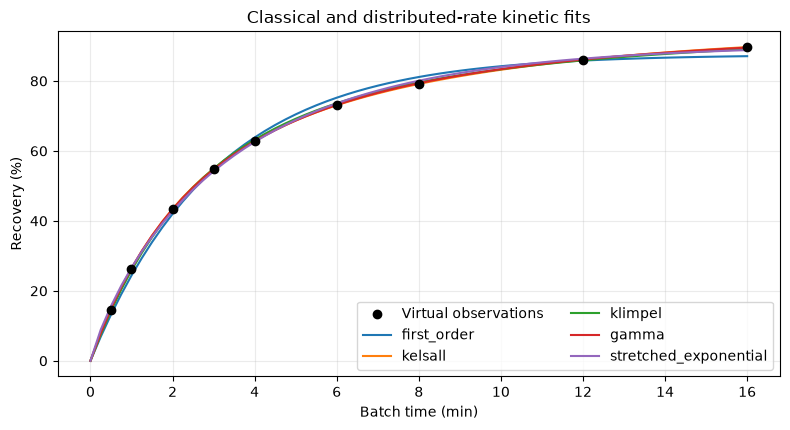

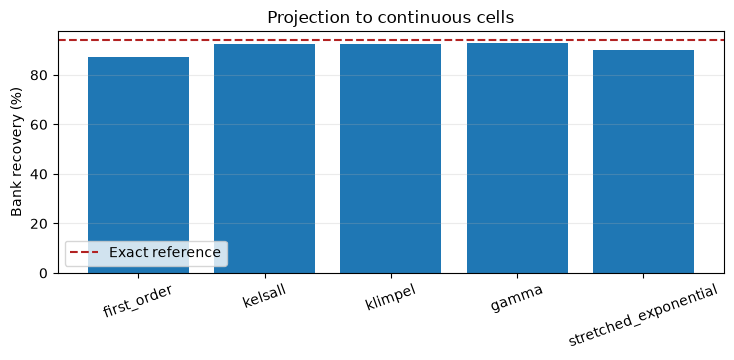

In [4]:
# Plot all fits on common batch observations, then compare the independent bank projection.
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.scatter(kinetics['times_min'], kinetics['batch_recovery_pct'], color='black', zorder=4, label='Virtual observations')
for m in models: ax.plot(kinetics['dense_times_min'], m['dense_pct'], label=m['id'])
ax.set(xlabel='Batch time (min)', ylabel='Recovery (%)', title='Classical and distributed-rate kinetic fits')
ax.grid(True, alpha=.25); ax.legend(ncol=2); fig.tight_layout()
fig, ax = plt.subplots(figsize=(7.5, 3.7))
ax.bar([m['id'] for m in models], [m['bank_projection_pct'] for m in models])
ax.axhline(kinetics['bank']['exact_true_flotation_pct'], color='firebrick', linestyle='--', label='Exact reference')
ax.set(ylabel='Bank recovery (%)', title='Projection to continuous cells'); ax.tick_params(axis='x', rotation=20)
ax.legend(); ax.grid(axis='y', alpha=.25); fig.tight_layout()

## Results

The first figure compares fits on the same virtual data; the second compares projections with the exact rate-distributed model. These report approximation error inside OreFlow's engine, not real-world predictive accuracy. Batch fit and bank projection answer different questions.

## Summary

The literature comparison makes both the strength and limit visible: multiple classical forms can fit a synthetic curve, but their bank predictions diverge. OreFlow reports the discrepancy instead of presenting animation as plant dynamics.

## References

- https://doi.org/10.1016/S0301-7516(99)00069-1
- https://doi.org/10.5277/ppmp170128
- https://doi.org/10.1016/j.mineng.2025.109246
- https://doi.org/10.1016/0301-7516(81)90019-3